In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_style("whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Upload Dataset

from google.colab import files

uploaded = files.upload()


Saving ai4i2020.csv to ai4i2020.csv


In [3]:

# Step 3: Load Dataset

df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first 5 records
df.head()


Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:

# Step 4: Understand Dataset Structure

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())


Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF      

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:

# Cell No. 5: Check Missing Values and Duplicate Records

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nTotal Duplicate Records:", df.duplicated().sum())


Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total Missing Values: 0

Total Duplicate Records: 0


Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


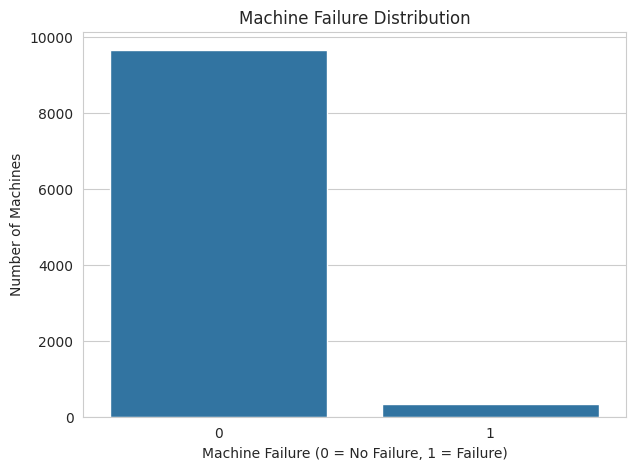

In [6]:

# Cell No. 6: Machine Failure Distribution

# Count machine failure and non-failure cases
failure_counts = df['Machine failure'].value_counts()

print("Machine Failure Distribution:")
print(failure_counts)

# Visualize the distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Machine failure')

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Machines")

plt.show()


In [7]:

# Cell No. 7: Calculate Failure Percentages

failure_percentage = df['Machine failure'].value_counts(normalize=True) * 100

print("Machine Failure Percentage:")
print(failure_percentage)

print("\nPercentage of Machines Without Failure:",
      round(failure_percentage.get(0, 0), 2), "%")

print("Percentage of Machines With Failure:",
      round(failure_percentage.get(1, 0), 2), "%")


Machine Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Percentage of Machines Without Failure: 96.61 %
Percentage of Machines With Failure: 3.39 %


### Exploratory Data Analysis – Initial Findings

The AI4I 2020 Predictive Maintenance dataset contains 10,000 records and 14 columns. Initial data quality analysis revealed that there are no missing values or duplicate records.

The target variable, Machine Failure, contains:
- 9,661 records (96.61%) representing machines without failure.
- 339 records (3.39%) representing machines with failure.

The analysis reveals a significant class imbalance in the dataset. Therefore, model evaluation must consider precision, recall and F1-score along with accuracy to ensure that machine failures are identified effectively.

Machine Type Counts:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


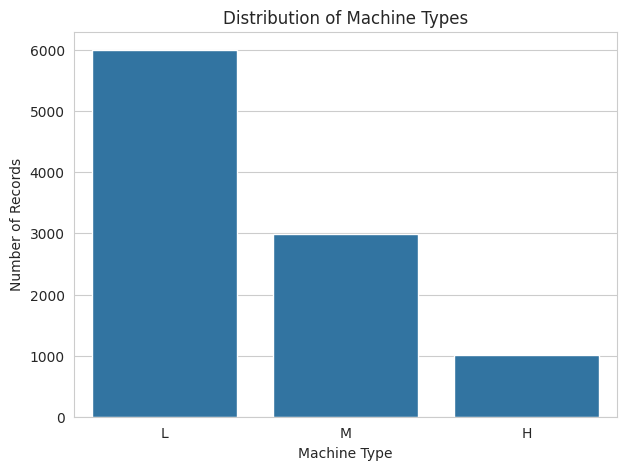

In [8]:

# Cell No. 8: Machine Type Distribution

print("Machine Type Counts:")
print(df['Type'].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Type', order=['L', 'M', 'H'])

plt.title("Distribution of Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Number of Records")

plt.show()


In [9]:

# Cell No. 9: Statistical Analysis of Machine Parameters

features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

print("Statistical Summary of Machine Parameters:")

display(df[features].describe())


Statistical Summary of Machine Parameters:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


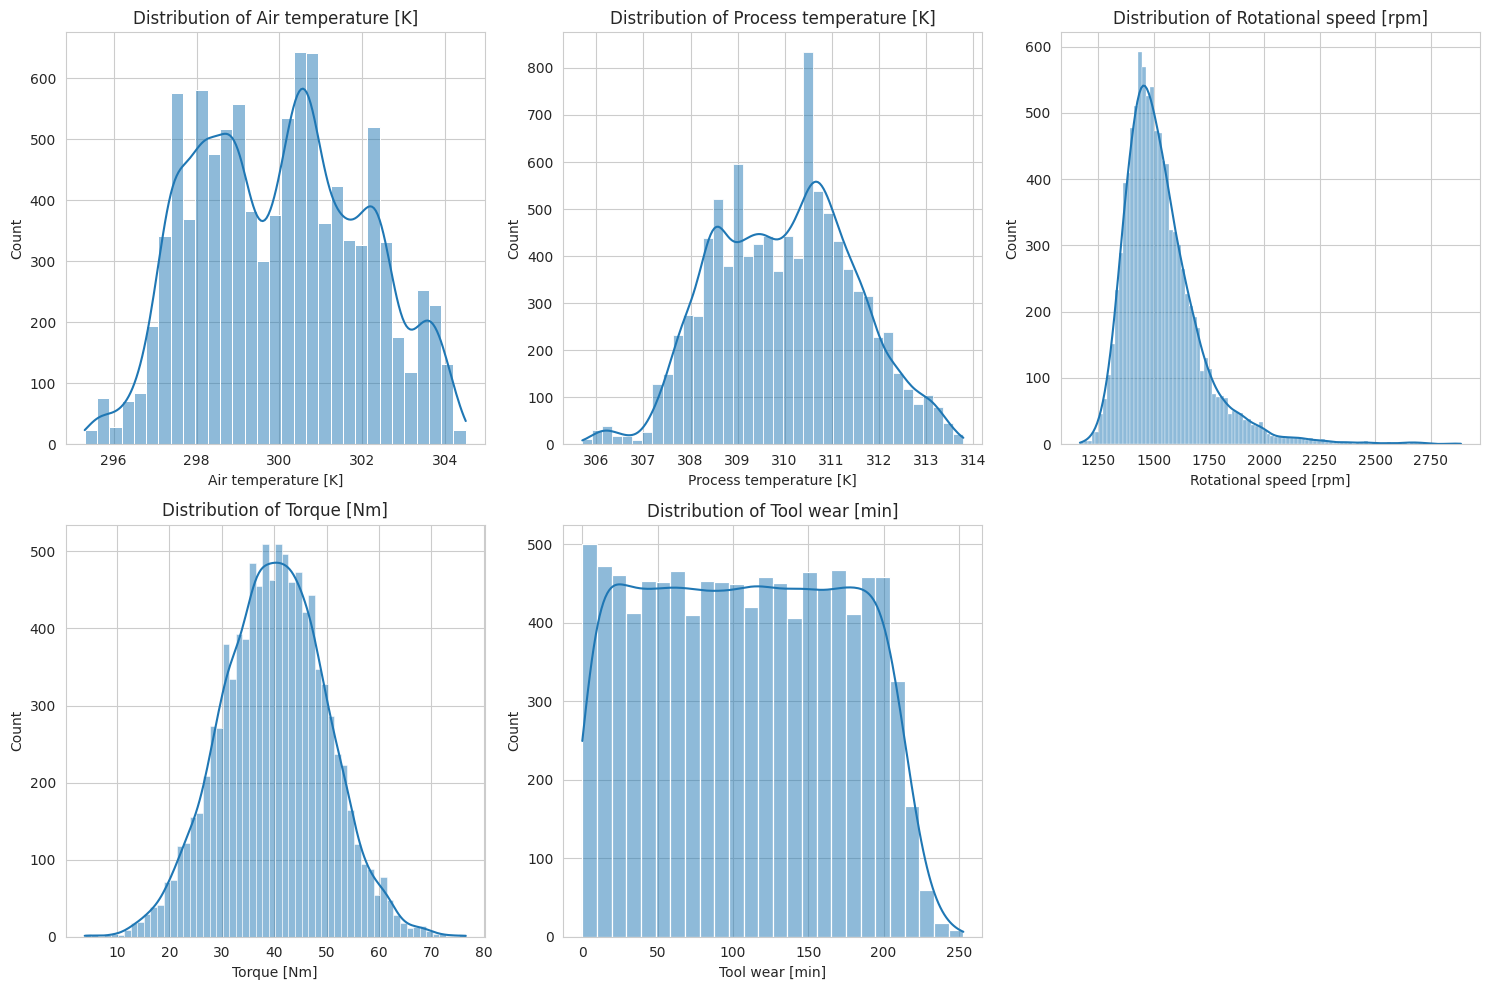

In [10]:

# Cell No. 10: Distribution of Machine Parameters

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)

    sns.histplot(data=df, x=feature, kde=True)

    plt.title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()


### Analysis of Machine Types and Operating Parameters (Cells 8–10)

In this section, we analysed the distribution of product types and examined the statistical properties of machine operating parameters. We used descriptive statistics and histograms to understand the data distribution, variation and patterns of air temperature, process temperature, rotational speed, torque and tool wear. This analysis provides an initial understanding of machine operating conditions and helps identify useful features for further investigation.

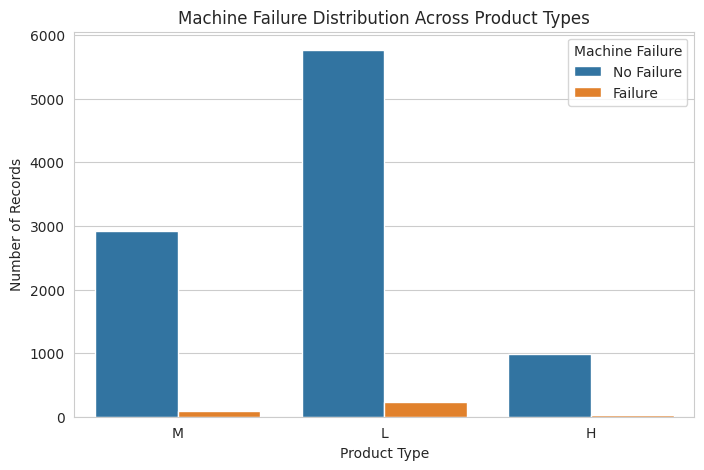

In [11]:

# Cell No. 11: Machine Failure Across Product Types

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Type', hue='Machine failure')

plt.title("Machine Failure Distribution Across Product Types")
plt.xlabel("Product Type")
plt.ylabel("Number of Records")

plt.legend(title="Machine Failure", labels=["No Failure", "Failure"])

plt.show()


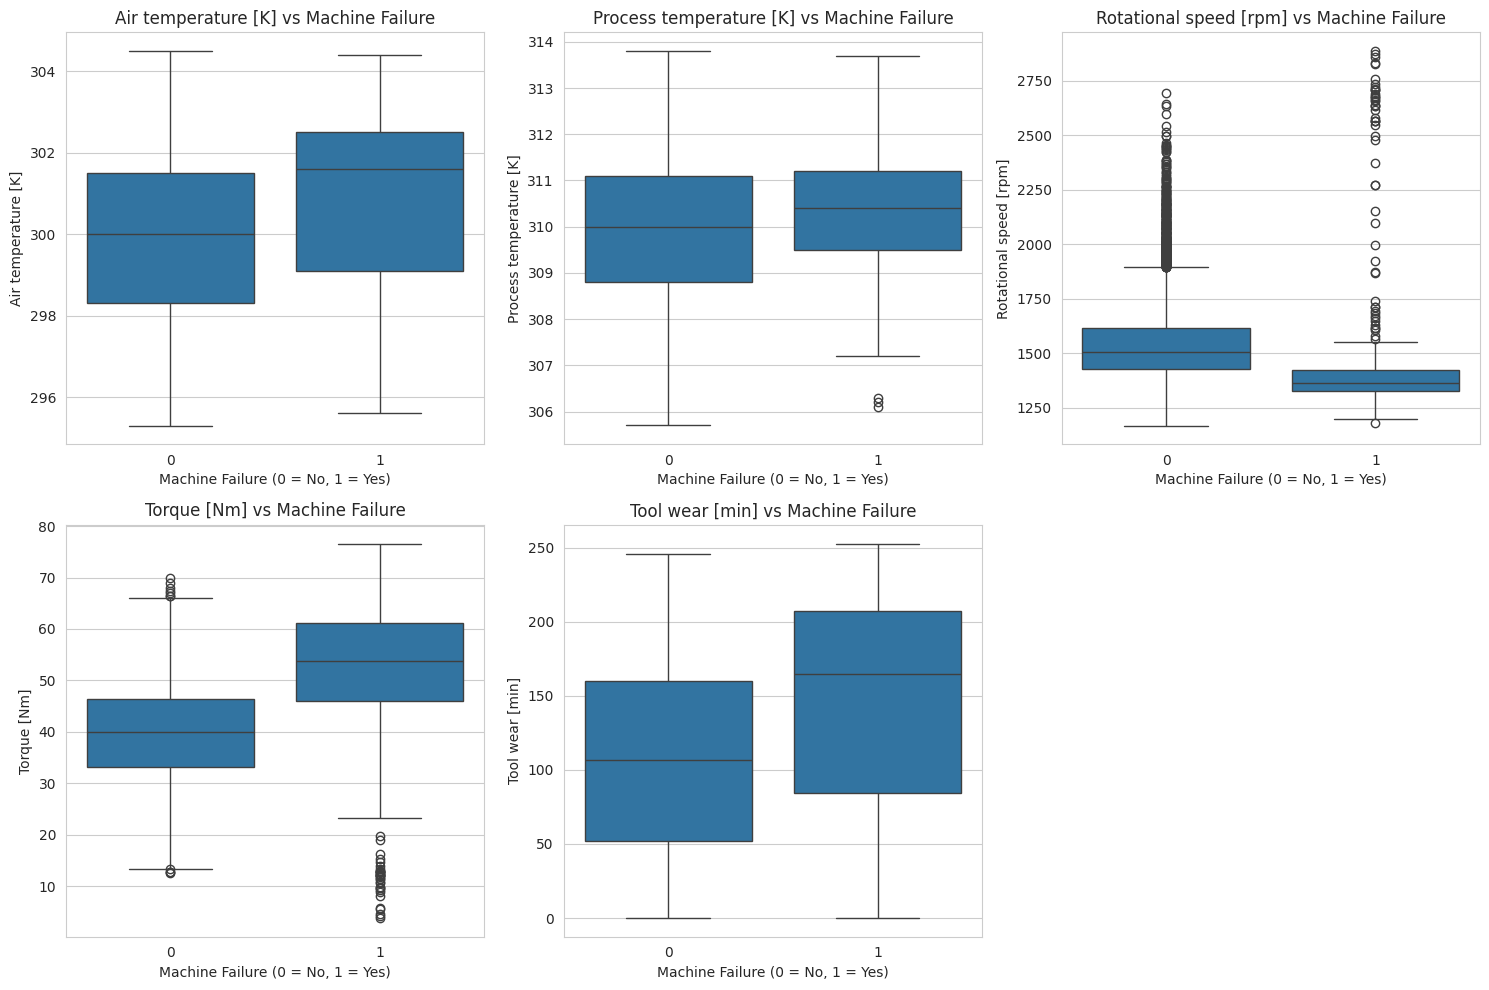

In [12]:

# Cell No. 12: Compare Machine Parameters Based on Failure

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(data=df, x='Machine failure', y=feature)

    plt.title(f'{feature} vs Machine Failure')
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()


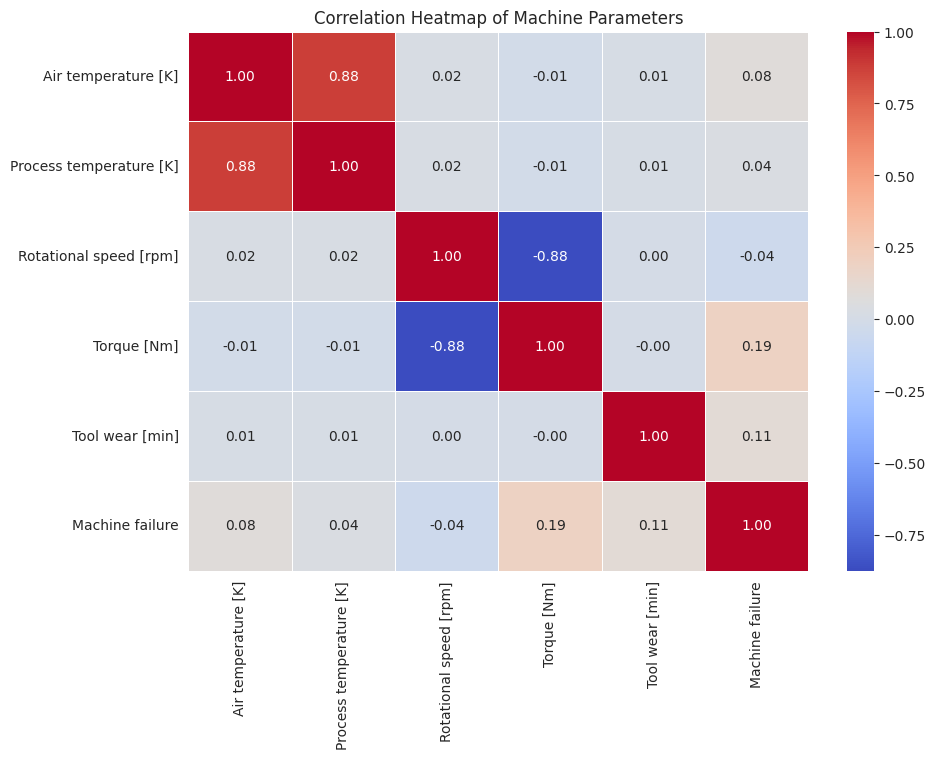

In [13]:

# Cell No. 13: Correlation Heatmap

# Select numerical columns
correlation_data = df[features + ['Machine failure']]

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Visualize correlation
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Machine Parameters")

plt.show()


### Machine Failure Pattern and Correlation Analysis (Cells 11–13)

In this section, we investigated the relationship between machine failure and different product types and operating parameters. Count plots were used to compare failures across product categories, while boxplots helped identify differences in machine operating conditions between failure and non-failure records. A correlation heatmap was also generated to examine relationships among numerical features. Torque showed the strongest positive linear correlation with machine failure (0.19), followed by tool wear (0.11). These findings provide useful insights for subsequent feature analysis and model development.

Failure Rate by Product Type (%):
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


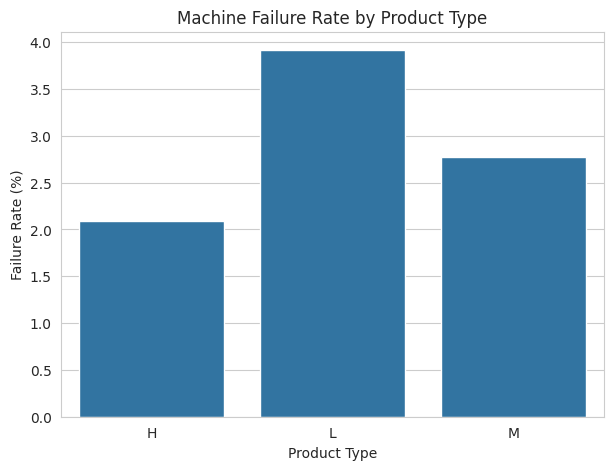

In [14]:

# Cell No. 14: Failure Rate by Product Type

failure_by_type = df.groupby('Type')['Machine failure'].mean() * 100

print("Failure Rate by Product Type (%):")
print(failure_by_type.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    x=failure_by_type.index,
    y=failure_by_type.values
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()


Failure Mode Counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


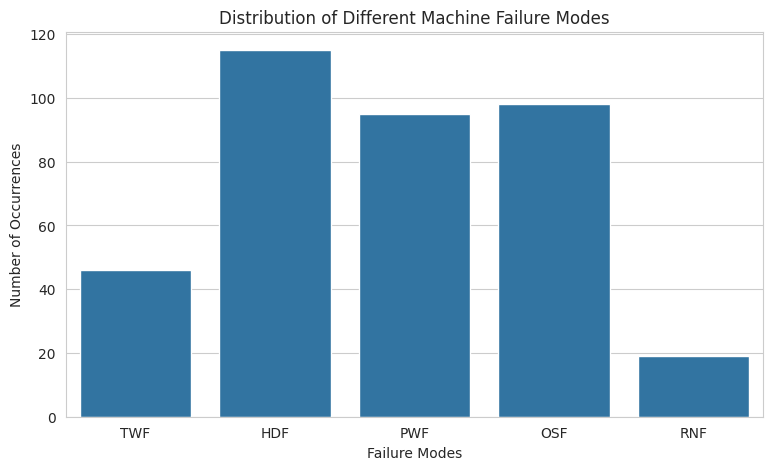

In [15]:

# Cell No. 15: Failure Mode Analysis

failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Calculate failure mode counts
mode_counts = df[failure_modes].sum()

print("Failure Mode Counts:")
print(mode_counts)

# Visualize failure modes
plt.figure(figsize=(9, 5))

sns.barplot(
    x=mode_counts.index,
    y=mode_counts.values
)

plt.title("Distribution of Different Machine Failure Modes")
plt.xlabel("Failure Modes")
plt.ylabel("Number of Occurrences")

plt.show()


In [16]:

# Cell No. 16: Generate EDA Summary

print("========== EDA SUMMARY ==========")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Missing Values:")
print(df.isnull().sum().sum())

print("\n3. Duplicate Records:")
print(df.duplicated().sum())

print("\n4. Machine Failure Counts:")
print(df['Machine failure'].value_counts())

print("\n5. Failure Percentage:")
print((df['Machine failure'].value_counts(normalize=True) * 100).round(2))

print("\n6. Failure Rate by Product Type:")
print((df.groupby('Type')['Machine failure'].mean() * 100).round(2))

print("\n7. Failure Mode Counts:")
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())

print("\n8. Correlation with Machine Failure:")
print(df[features + ['Machine failure']].corr()['Machine failure'].round(3))

print("\n========== END OF SUMMARY ==========")


========== EDA SUMMARY ==========

1. Dataset Shape:
(10000, 14)

2. Missing Values:
0

3. Duplicate Records:
0

4. Machine Failure Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

5. Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

6. Failure Rate by Product Type:
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64

7. Failure Mode Counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

8. Correlation with Machine Failure:
Air temperature [K]        0.083
Process temperature [K]    0.036
Rotational speed [rpm]    -0.044
Torque [Nm]                0.191
Tool wear [min]            0.105
Machine failure            1.000
Name: Machine failure, dtype: float64

========== END OF SUMMARY ==========


### Detailed Failure Analysis and EDA Summary (Cells 14–16)

In this section, we calculated machine failure rates across different product types and analysed individual failure modes. Product type L showed the highest failure rate of 3.92%, followed by M at 2.77% and H at 2.09%. Heat Dissipation Failure (HDF) recorded the highest number of failure flags (115).

The overall analysis confirmed that the dataset contains no missing or duplicate records. However, a significant class imbalance was observed, with only 3.39% of records representing machine failures. These findings will guide our data preprocessing, model selection and evaluation strategy.


In [17]:

# Cell No. 17: Create a Copy of the Dataset

# Create a copy to preserve original data
data = df.copy()

print("Dataset copy created successfully!")
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", data.shape)


Dataset copy created successfully!
Original Dataset Shape: (10000, 14)
Working Dataset Shape: (10000, 14)


In [18]:

# Cell No. 18: Remove Unnecessary Columns

# Columns that should not be used as model inputs
columns_to_drop = [
    'UDI',
    'Product ID',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

# Remove unnecessary columns
data = data.drop(columns=columns_to_drop)

print("Unnecessary columns removed successfully!")
print("Remaining Columns:")
print(data.columns.tolist())

print("\nUpdated Dataset Shape:", data.shape)


Unnecessary columns removed successfully!
Remaining Columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']

Updated Dataset Shape: (10000, 7)


In [19]:

# Cell No. 19: Separate Features and Target

# Input features
X = data.drop('Machine failure', axis=1)

# Target variable
y = data['Machine failure']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)


Features Shape: (10000, 6)
Target Shape: (10000,)

Input Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target Variable:
Machine failure


In [20]:

# Cell No. 20: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nFailure Distribution in Training Data:")
print(y_train.value_counts())

print("\nFailure Distribution in Testing Data:")
print(y_test.value_counts())


Training Features: (8000, 6)
Testing Features: (2000, 6)

Training Target: (8000,)
Testing Target: (2000,)

Failure Distribution in Training Data:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Failure Distribution in Testing Data:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [21]:

# Cell No. 21: Feature Encoding and Scaling

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_features = ['Type']

numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nProcessed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)


Preprocessing completed successfully!

Processed Training Shape: (8000, 8)
Processed Testing Shape: (2000, 8)


### Data Preprocessing and Feature Engineering (Cells 17–21)

In this phase, the original dataset was copied and unnecessary columns, including identifiers and failure-mode indicators, were removed to prevent data leakage. The remaining data was divided into input features (X) and the target variable (y). The dataset was split into 80% training data and 20% testing data using stratified sampling to maintain class proportions. Categorical data was transformed using One-Hot Encoding, while numerical features were standardized using StandardScaler. The final processed dataset contained 8 features, with 8,000 training records and 2,000 testing records.

In [22]:

# Cell No. 22: Import ML Algorithms and Create Pipelines

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Define six machine learning models
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        class_weight='balanced',
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'SVM': SVC(
        class_weight='balanced',
        probability=True,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

# Create preprocessing and model pipelines
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

print("Six Machine Learning Pipelines Created Successfully!")

for name in pipelines:
    print("-", name)


Six Machine Learning Pipelines Created Successfully!
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN
- Gradient Boosting


In [23]:

# Cell No. 23: 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate

# Maintain class distribution in every fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Store cross-validation results
cv_results = {}

for name, pipeline in pipelines.items():

    print(f"\nTraining: {name}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results[name] = {
        metric: scores[f'test_{metric}'].mean()
        for metric in scoring
    }

    print("F1 Score:", round(cv_results[name]['f1'], 4))

# Convert results into a DataFrame
results_df = pd.DataFrame(cv_results).T

print("\n========== MODEL COMPARISON ==========")

display(results_df.round(4))



Training: Logistic Regression
F1 Score: 0.2346

Training: Decision Tree
F1 Score: 0.6158

Training: Random Forest
F1 Score: 0.5296

Training: SVM
F1 Score: 0.421

Training: KNN
F1 Score: 0.4522

Training: Gradient Boosting
F1 Score: 0.709

========== MODEL COMPARISON ==========


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.8225,0.1374,0.8044,0.2346,0.8965
Decision Tree,0.9765,0.6920,0.5610,0.6158,0.7760
Random Forest,0.9774,0.8965,0.3766,0.5296,0.9619
SVM,0.9191,0.2783,0.8670,0.4210,0.9602
KNN,0.9740,0.7949,0.3174,0.4522,0.8471
Gradient Boosting,0.9834,0.8725,0.6017,0.7090,0.9733


In [24]:

# Cell No. 24: Display Model Comparison Results

print("========== MODEL PERFORMANCE COMPARISON ==========")

print(results_df.round(4).to_string())

print("\n========== BEST MODEL BY F1 SCORE ==========")

best_model = results_df['f1'].idxmax()

print("Best Model:", best_model)
print("F1 Score:", round(results_df.loc[best_model, 'f1'], 4))


========== MODEL PERFORMANCE COMPARISON ==========
                     accuracy  precision  recall      f1  roc_auc
Logistic Regression    0.8225     0.1374  0.8044  0.2346   0.8965
Decision Tree          0.9765     0.6920  0.5610  0.6158   0.7760
Random Forest          0.9774     0.8965  0.3766  0.5296   0.9619
SVM                    0.9191     0.2783  0.8670  0.4210   0.9602
KNN                    0.9740     0.7949  0.3174  0.4522   0.8471
Gradient Boosting      0.9834     0.8725  0.6017  0.7090   0.9733

========== BEST MODEL BY F1 SCORE ==========
Best Model: Gradient Boosting
F1 Score: 0.709


### Machine Learning Model Training and Comparison (Cells 22–24)

Six classification algorithms were implemented using Scikit-learn pipelines: Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, K-Nearest Neighbors and Gradient Boosting. Each model was evaluated using 5-fold stratified cross-validation with accuracy, precision, recall, F1-score and ROC-AUC metrics. Gradient Boosting achieved the highest F1-score of 0.7090 and accuracy of 98.34%, making it the best-performing candidate in the initial model comparison. SVM achieved the highest recall of 86.70%, while Random Forest achieved the highest precision of 89.65%.

In [25]:

# Cell No. 25: Hyperparameter Tuning - Gradient Boosting

from sklearn.model_selection import GridSearchCV

# Select Gradient Boosting pipeline
gb_pipeline = pipelines['Gradient Boosting']

# Define hyperparameter combinations
param_grid = {
    'model__n_estimators': [100, 150],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
    'model__min_samples_leaf': [2, 5]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
grid_search.fit(X_train, y_train)

# Display best parameters
print("\nBest Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Hyperparameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__n_estimators': 150}

Best Cross-Validation F1 Score:
0.7241


In [26]:

# Cell No. 26: Compare Original and Tuned Gradient Boosting

original_f1 = results_df.loc['Gradient Boosting', 'f1']
tuned_f1 = grid_search.best_score_

comparison = pd.DataFrame({
    'Model': ['Original Gradient Boosting', 'Tuned Gradient Boosting'],
    'Cross-Validation F1 Score': [original_f1, tuned_f1]
})

display(comparison.round(4))

if tuned_f1 > original_f1:
    print("Hyperparameter tuning improved the F1 score!")
elif tuned_f1 == original_f1:
    print("Both models achieved the same F1 score.")
else:
    print("Original model performed better than the tuned model.")


,Model,Cross-Validation F1 Score
0,Original Gradient Boosting,0.7090
1,Tuned Gradient Boosting,0.7241


Hyperparameter tuning improved the F1 score!


In [27]:

# Cell No. 27: Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Select tuned model
best_model_pipeline = grid_search.best_estimator_

# Predict on test data
y_pred = best_model_pipeline.predict(X_test)

# Calculate prediction probabilities
y_prob = best_model_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("FINAL MODEL PERFORMANCE")

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


FINAL MODEL PERFORMANCE

Accuracy: 0.987
Precision: 0.875
Recall: 0.7206
F1 Score: 0.7903
ROC-AUC: 0.9686

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.88      0.72      0.79        68

    accuracy                           0.99      2000
   macro avg       0.93      0.86      0.89      2000
weighted avg       0.99      0.99      0.99      2000



Hyperparameter Tuning and Final Model Evaluation:
GridSearchCV was used to optimize the Gradient Boosting Classifier by testing 16 hyperparameter combinations using 5-fold cross-validation. The best configuration achieved a cross-validation F1-score of 0.7241. The tuned model was then evaluated on the previously unused test dataset and achieved 98.70% accuracy, 87.50% precision, 72.06% recall, 79.03% F1-score and 96.86% ROC-AUC. These results indicate strong overall performance, although some actual machine failures were not detected.

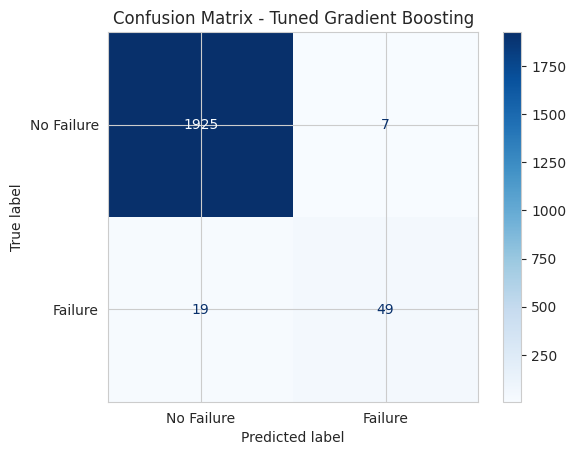

Confusion Matrix:
[[1925    7]
 [  19   49]]


In [28]:

# Cell No. 28: Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Tuned Gradient Boosting")
plt.show()

print("Confusion Matrix:")
print(cm)


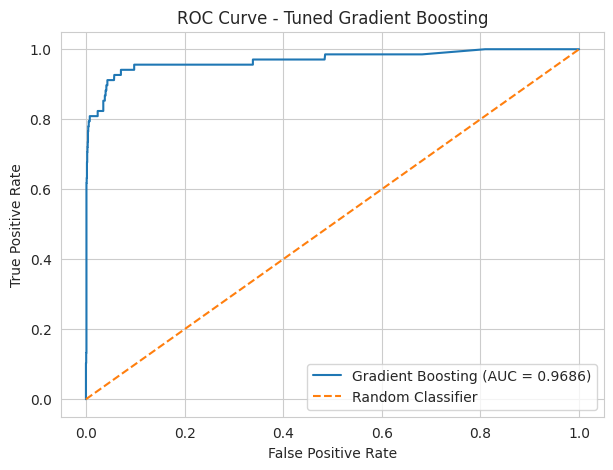

In [29]:

# Cell No. 29: ROC Curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Gradient Boosting")
plt.legend()
plt.grid(True)
plt.show()


,Feature,Importance
3,num__Torque [Nm],0.3955
2,num__Rotational speed [rpm],0.1843
4,num__Tool wear [min],0.1672
0,num__Air temperature [K],0.1354
1,num__Process temperature [K],0.0902
6,cat__Type_L,0.0221
7,cat__Type_M,0.0047
5,cat__Type_H,0.0008


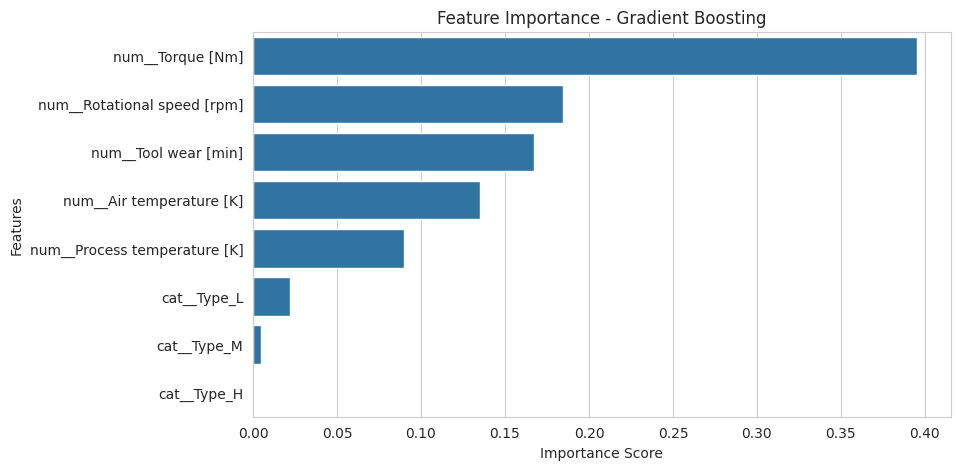

In [30]:

# Cell No. 30: Feature Importance

best_model = best_model_pipeline.named_steps["model"]

feature_names = best_model_pipeline.named_steps[
    "preprocessing"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Feature Importance - Gradient Boosting")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()


Hyperparameter tuning was performed on the Gradient Boosting classifier using GridSearchCV with 5-fold stratified cross-validation. The tuned model achieved a cross-validation F1-score of 0.7241, improving upon the original score of 0.7090. The final model was evaluated on an unseen test dataset of 2,000 records and achieved 98.70% accuracy, 87.50% precision, 72.06% recall, 79.03% F1-score and 96.86% ROC-AUC. The confusion matrix showed 49 correctly detected failures and 19 missed failures. Feature-importance analysis identified torque, rotational speed and tool wear as the most influential predictive features.

In [31]:
# Cell No. 31: Save the Final Trained Model

import joblib
import os

# Save the complete pipeline
joblib.dump(best_model_pipeline, "predictive_maintenance_model.pkl")

# Check whether the model was saved
if os.path.exists("predictive_maintenance_model.pkl"):
    print("Model saved successfully!")

    print("File size:",
          round(os.path.getsize("predictive_maintenance_model.pkl") / 1024, 2),
          "KB")

Model saved successfully!
File size: 196.39 KB


In [32]:
from google.colab import files

files.download("predictive_maintenance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import os

print("Current files:")
print(os.listdir())

print("Model exists:",
      os.path.exists("predictive_maintenance_model.pkl"))

Current files:
['.config', 'predictive_maintenance_model.pkl', 'ai4i2020.csv', 'sample_data']
Model exists: True


In [36]:
from google.colab import files

files.download("predictive_maintenance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>